# 01 · EDA y limpieza
**Objetivo:** diagnosticar la calidad *real* de `music_genre.csv`, limpiarlo con reglas sin estado (seguras antes del split) y entender qué variables separan los 10 géneros.

| Entrada | Salida |
|---|---|
| `datos/raw/music_genre.csv` (intacto) | `datos/processed/music_genre_limpio.csv` |

Toda la lógica vive en `src/funciones.py`; aquí solo se ejecuta e interpreta.

In [ ]:
# === Solo Google Colab (en Jupyter local esta celda no hace nada) ===
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    # Ajusta esta ruta si subiste la carpeta a otro lugar de tu Drive
    RUTA_PROYECTO = "/content/drive/MyDrive/proyecto-clasificacion-musical"
    os.chdir(RUTA_PROYECTO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # os.environ["MODO_RAPIDO"] = "1"   # descomenta para una corrida rápida (~10 min en vez de ~85)

In [1]:
# === Configuración común ===
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "funciones.py").exists())
sys.path.insert(0, str(RAIZ / "src"))
import funciones as F

warnings.filterwarnings("ignore", message=".*Early stopping criterion not reached.*")  # IterativeImputer
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
rutas = F.obtener_rutas(RAIZ)
# MODO_RAPIDO=1 (variable de entorno) reduce muestras y presupuestos para iterar rápido.
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"
print("Raíz:", rutas.raiz, "| modo rápido:", MODO_RAPIDO)

Raíz: <raíz> | modo rápido: False


## 1. Diagnóstico de calidad
`isnull()` solo ve 5 filas vacías. El faltante real está **disfrazado** con valores centinela: `duration_ms = -1`, `tempo = '?'` (que además convierte la columna en texto) y `artist_name = 'empty_field'`.

In [2]:
raw = F.cargar_raw(rutas.raw / "music_genre.csv")
print(raw.shape)
print("Filas 100% nulas:", raw.isna().all(axis=1).sum())
F.diagnosticar_calidad(raw)

(50005, 18)
Filas 100% nulas: 5


,dtype,nulos_explicitos,centinelas,faltante_real,pct_faltante_real,n_unicos
columna,,,,,,
tempo,str,5,4980,4985,9.9700,29394
duration_ms,float64,5,4939,4944,9.8900,26028
artist_name,str,5,2489,2494,4.9900,6863
instance_id,float64,5,0,5,0.0100,50000
acousticness,float64,5,0,5,0.0100,4193
track_name,str,5,0,5,0.0100,41699
danceability,float64,5,0,5,0.0100,1088
energy,float64,5,0,5,0.0100,2085
instrumentalness,float64,5,0,5,0.0100,5131


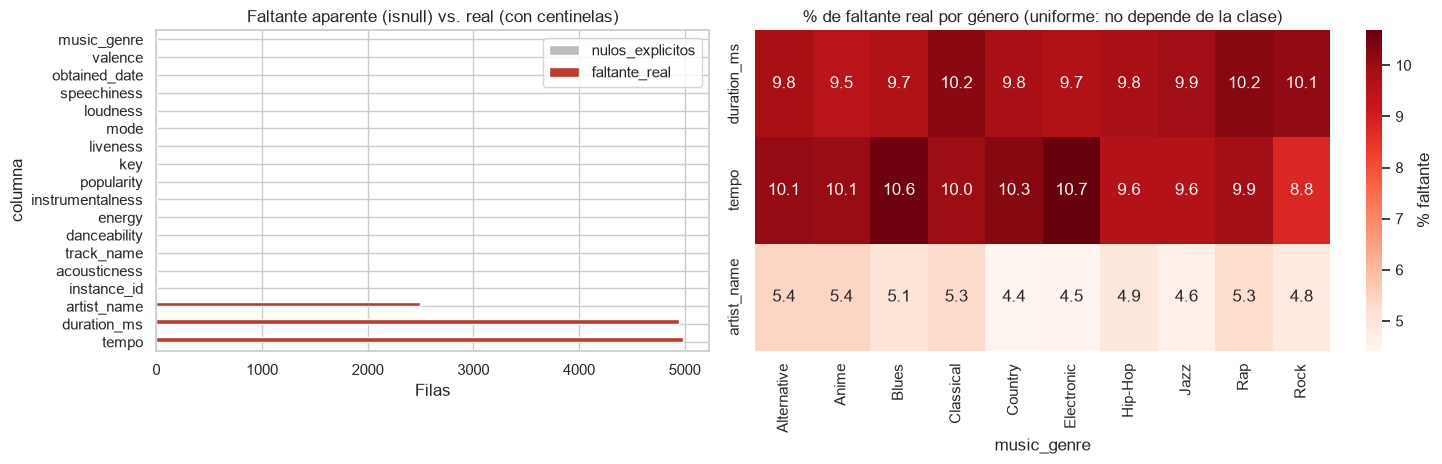

In [3]:
fig = F.grafico_faltantes(raw)

**Lectura:** el faltante real es ~20 veces mayor que el que muestra `isnull()`. El % de faltante es casi idéntico en los 10 géneros (~10 % en `tempo` y `duration_ms`), primera señal de que el faltante **no depende de la clase**.

## 2. Duplicados
Se revisan duplicados exactos y duplicados **por canción** (`track_name + artist_name`). Se excluye `empty_field`: con artista desconocido, dos títulos iguales ("Intro", "Home") no son necesariamente la misma canción.

In [4]:
dup = F.resumen_duplicados(F.reemplazar_centinelas(raw.dropna(how="all")))
print({k: v for k, v in dup.items() if not isinstance(v, pd.Series)})
display(dup["combinaciones_mas_frecuentes"].to_frame("grupos"))
dup["generos_afectados"].to_frame("filas")

{'duplicados_exactos': 0, 'duplicados_exactos_sin_id': 0, 'filas_duplicadas_por_cancion': 3802, 'grupos_duplicados': 3606, 'grupos_con_generos_distintos': 3606}


,grupos
music_genre,
Hip-Hop + Rap,1517
Alternative + Rock,535
Country + Rock,291
Electronic + Jazz,166
Alternative + Hip-Hop,141
Alternative + Rap,136
Blues + Rock,134
Blues + Jazz,101
Rap + Rock,74


,filas
music_genre,
Rap,1884
Hip-Hop,1769
Rock,1186
Alternative,1110
Country,450
Jazz,347
Blues,347
Electronic,209
Classical,64


**Hallazgo clave:** no hay duplicados exactos (el `instance_id` es único), pero hay **3 835 filas duplicadas por canción y todos los grupos tienen géneros distintos**: la misma canción, con el mismo vector acústico, aparece como *Hip-Hop* y *Rap* (≈1 500 grupos), *Alternative* y *Rock*, *Country* y *Rock*…

Esto es **ruido de etiqueta multi-género**, y conservarlo tiene dos costes:
1. **Fuga entre train y test:** una copia en train y otra en test hace que el test evalúe un vector que el modelo ya vio.
2. **Error irreducible:** el mismo `x` con dos `y` distintos impone un techo de exactitud artificial.

**Decisión:** dejar una fila por canción y elegir la etiqueta **al azar con semilla**. `keep='first'` sesgaría el resultado porque el CSV está ordenado por género. Consecuencia: Rap/Hip-Hop/Rock/Alternative pierden más filas y aparece un **desbalanceo real** (se trata en el cuadernillo 02).

## 3. Limpieza (solo reglas sin estado)

In [5]:
df, bitacora = F.limpiar_dataset(raw)
display(bitacora)
df[F.OBJETIVO].value_counts().to_frame("canciones")

,paso,filas,eliminadas
0,0. raw,50005,0
1,1. sin filas 100% nulas,50000,5
2,2. centinelas -> NaN,50000,0
3,3. sin duplicados exactos,50000,0
4,4. una fila por canción,46198,3802


,canciones
music_genre,
Anime,4982
Classical,4963
Electronic,4903
Blues,4830
Jazz,4824
Country,4765
Alternative,4413
Rock,4365
Hip-Hop,4115


## 4. Mecanismo del faltante: ¿MCAR, MAR o MNAR?
La forma de imputar depende de **por qué** falta el dato.
* **χ² faltante × género:** ¿cambia el % de faltante según el género?
* **Mann-Whitney faltante vs. observado:** ¿las filas con `tempo` faltante difieren en otras variables (MAR)?

In [6]:
display(F.prueba_mcar_por_genero(df, ["tempo", "duration_ms", F.COLUMNA_ARTISTA]))
display(F.prueba_mar_por_variables(df, "tempo", F.COLUMNAS_NUMERICAS).head(5))
F.prueba_mar_por_variables(df, "duration_ms", F.COLUMNAS_NUMERICAS).head(5)

,pct_faltante,chi2,gl,p_valor,cramer_v
variable,,,,,
tempo,9.9600,16.2000,9,0.0628,0.0125
duration_ms,9.9000,3.5400,9,0.9393,0.0000
artist_name,5.3900,33.8800,9,0.0001,0.0232


,mediana_faltante,mediana_observado,p_valor,efecto_r
variable,,,,
popularity,43.0000,43.0000,0.0428,0.0182
danceability,0.5590,0.5640,0.3018,0.0093
loudness,-7.3120,-7.3780,0.3198,-0.0089
speechiness,0.0475,0.0481,0.3478,0.0084
acousticness,0.1460,0.1530,0.4181,0.0073


,mediana_faltante,mediana_observado,p_valor,efecto_r
variable,,,,
energy,0.6300,0.6400,0.1166,0.0141
tempo,120.0085,119.7550,0.1387,-0.0140
valence,0.4370,0.4470,0.1219,0.0139
acousticness,0.1550,0.1520,0.1613,-0.0126
loudness,-7.3990,-7.3650,0.4530,0.0067


### Justificación de la imputación (se ejecuta en el Pipeline del cuadernillo 02)
| Variable | % faltante | Diagnóstico | Decisión | Por qué no la alternativa |
|---|---|---|---|---|
| `tempo` | ~10 % | χ² p≈0.06, V de Cramér≈0.01; tamaños de efecto MAR despreciables → compatible con **MCAR** | **IterativeImputer** (MICE con BayesianRidge) + indicador de faltante | *Mediana por género*: usa `y`, que **no existe en producción** (no se conoce el género de una canción nueva), y además filtra la etiqueta a las variables (fuga). *Eliminar*: ~19 % de las filas tienen algún faltante; con MCAR no sesga, pero desperdicia información y no sirve para predecir canciones con faltantes. |
| `duration_ms` | ~10 % | p≈0.94 → MCAR | Igual que `tempo` (log después de imputar) | La mediana global ignora que la duración se relaciona con instrumentalness/acousticness (clásica = piezas largas). |
| `artist_name` | ~5 % | V≈0.02: el faltante depende muy poco del género | Categoría constante `__desconocido__` → Target Encoding | Imputar un artista "probable" inventaría una identidad. El nivel propio deja que el encoder aprenda la prior de los desconocidos. |

**Garantía anti-fuga:** los imputadores se ajustan dentro del Pipeline, solo con los folds de entrenamiento. El cuadernillo 02 compara Mediana, KNN e Iterative con un experimento de enmascaramiento **sobre train**.

## 5. EDA univariado
### 5.1 Variable objetivo

,raw,limpio
Alternative,5000,4413
Anime,5000,4982
Blues,5000,4830
Classical,5000,4963
Country,5000,4765
Electronic,5000,4903
Hip-Hop,5000,4115
Jazz,5000,4824
Rap,5000,4038
Rock,5000,4365


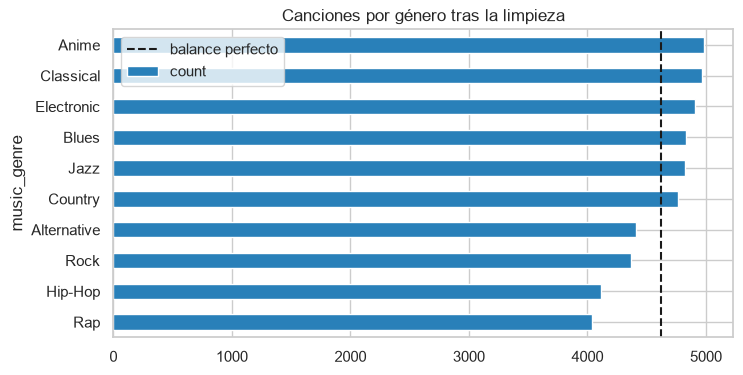

In [7]:
escenarios = {"raw": raw[F.OBJETIVO].dropna(), "limpio": df[F.OBJETIVO]}
display(F.comparar_distribuciones(escenarios))
ax = df[F.OBJETIVO].value_counts().sort_values().plot.barh(figsize=(8, 4), color="#2980b9",
                                                           title="Canciones por género tras la limpieza")
ax.axvline(len(df) / df[F.OBJETIVO].nunique(), ls="--", c="k", label="balance perfecto"); ax.legend();

### 5.2 Variables numéricas: forma de la distribución

In [8]:
desc = df[F.COLUMNAS_NUMERICAS].describe().T
desc["asimetría"] = df[F.COLUMNAS_NUMERICAS].skew()
desc["% ceros"] = (df[F.COLUMNAS_NUMERICAS] == 0).mean() * 100
desc

,count,mean,std,min,25%,50%,75%,max,asimetría,% ceros
popularity,46198.0000,43.1676,15.5022,0.0000,33.0000,43.0000,54.0000,99.0000,-0.2402,1.5001
acousticness,46198.0000,0.3159,0.3468,0.0000,0.0206,0.1520,0.5830,0.9960,0.8296,0.0022
danceability,46198.0000,0.5528,0.1789,0.0596,0.4360,0.5630,0.6810,0.9860,-0.2949,0.0000
duration_ms,41623.0000,246579.9452,112480.2139,15509.0000,190312.0000,227867.0000,277160.0000,4830606.0000,6.5377,0.0000
energy,46198.0000,0.5948,0.2693,0.0008,0.4200,0.6390,0.8160,0.9990,-0.5440,0.0000
instrumentalness,46198.0000,0.1918,0.3323,0.0000,0.0000,0.0002,0.2100,0.9960,1.4015,28.7047
liveness,46198.0000,0.1937,0.1626,0.0097,0.0967,0.1260,0.2420,1.0000,2.2688,0.0000
loudness,46198.0000,-9.2992,6.3201,-47.0460,-11.1318,-7.3680,-5.1900,3.7440,-1.8055,0.0022
speechiness,46198.0000,0.0901,0.0982,0.0223,0.0359,0.0480,0.0922,0.9420,2.6196,0.0000
tempo,41597.0000,119.9798,30.6948,34.3470,94.9630,119.8750,140.5180,220.2760,0.3199,0.0000


**Lectura:** `duration_ms`, `speechiness`, `liveness` e `instrumentalness` tienen asimetría fuerte, e `instrumentalness` tiene inflación de ceros. Justifica las transformaciones `log`/`log1p` del cuadernillo 02 y el uso de pruebas no paramétricas.

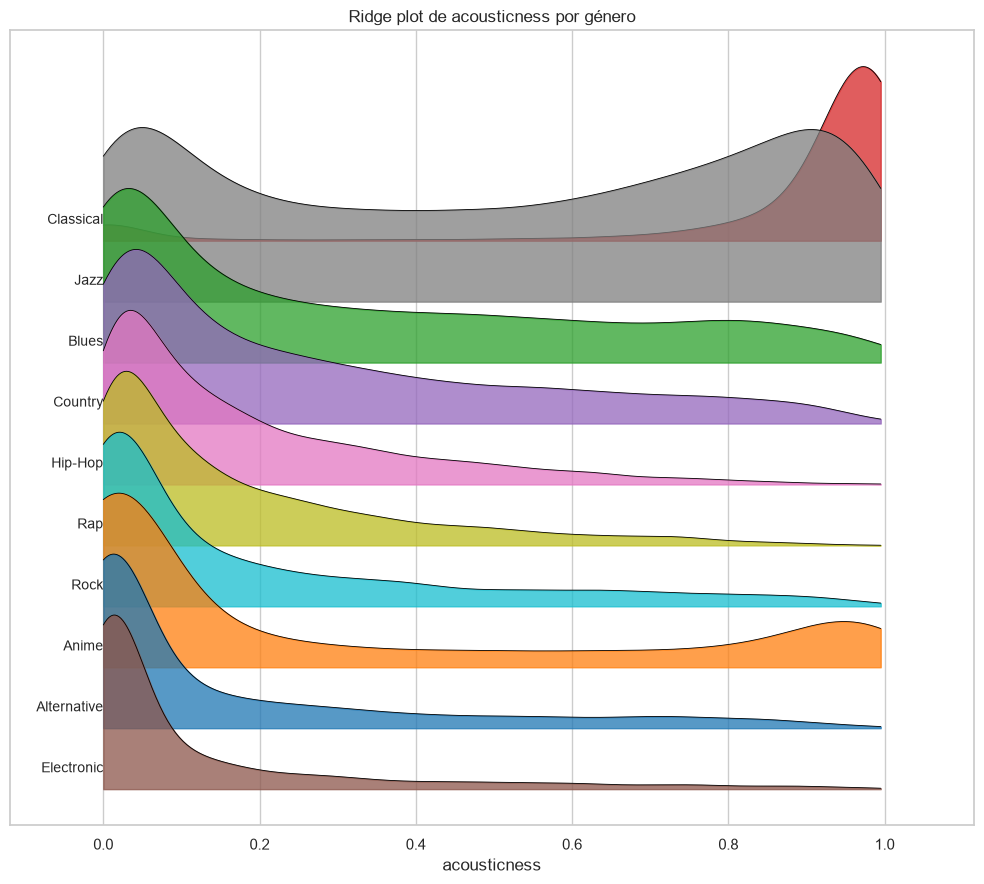

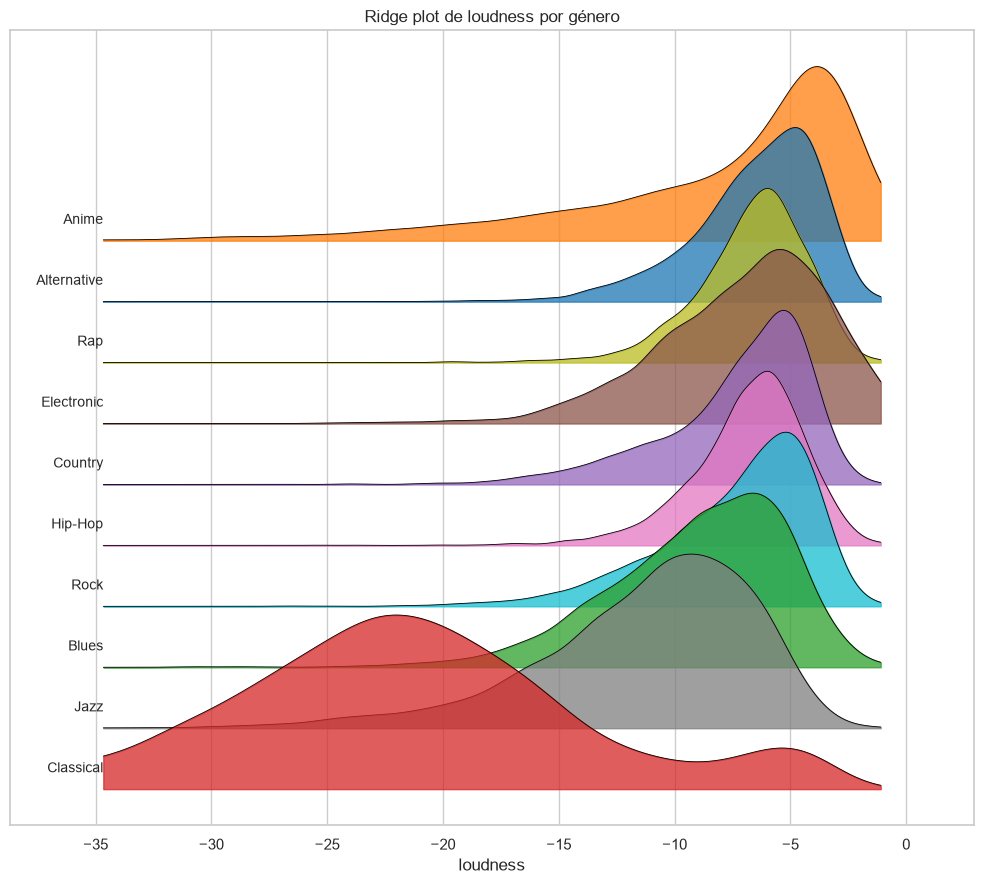

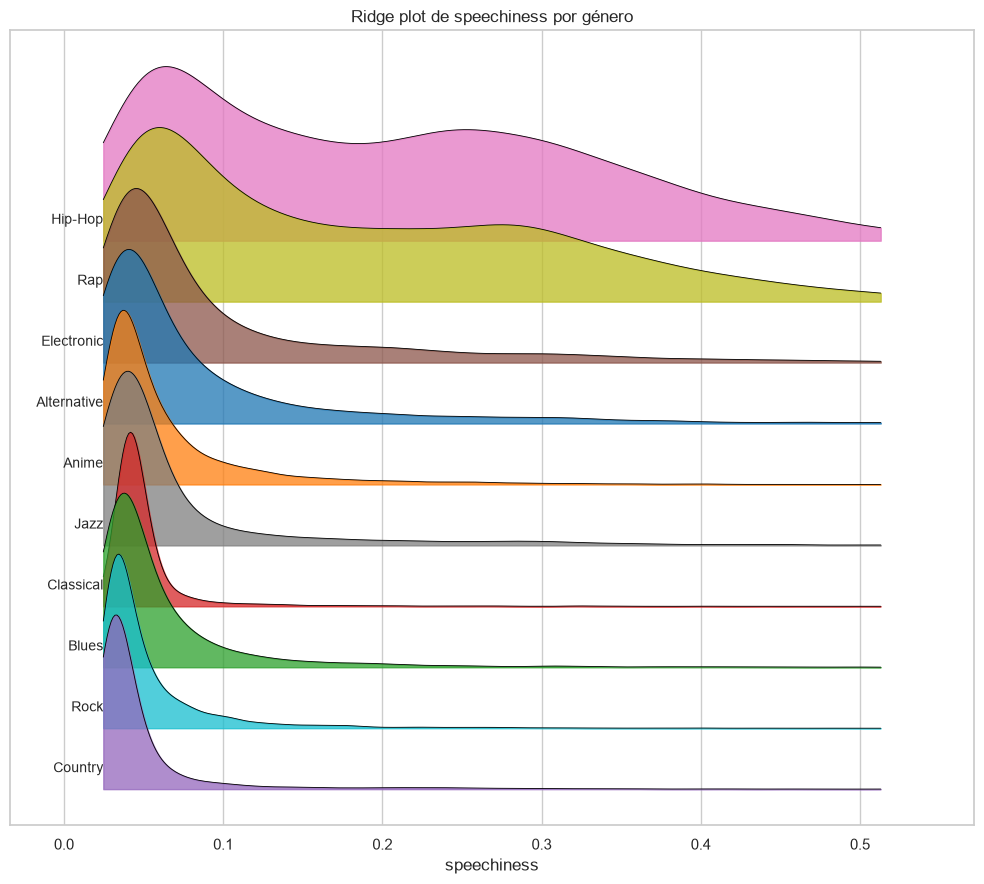

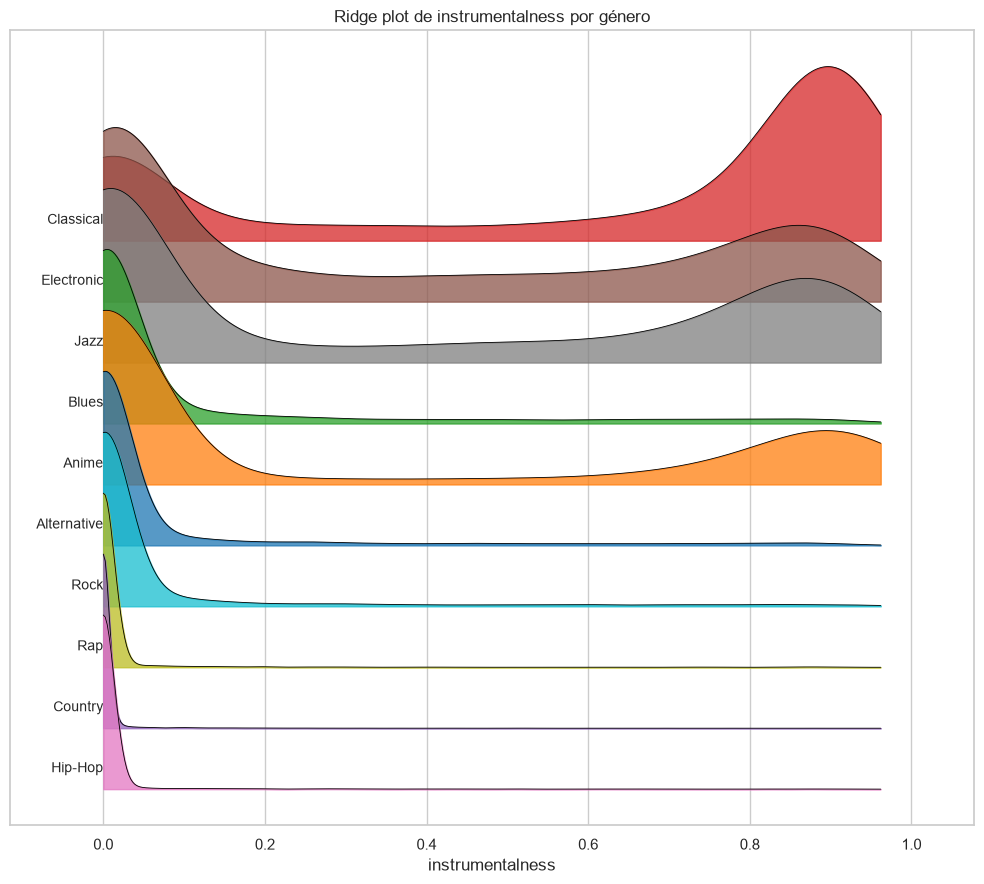

In [9]:
for col in ["acousticness", "loudness", "speechiness", "instrumentalness"]:
    F.grafico_ridge(df, col)

## 6. EDA bivariado (variable vs. género)
Con n ≈ 46 000 cualquier diferencia es "significativa", así que el ranking se hace con el **tamaño de efecto** η²_H de Kruskal-Wallis.

In [10]:
kw = F.kruskal_por_genero(df, F.COLUMNAS_NUMERICAS)
display(kw)
pd.Series({c: F.cramer_v(df[c], df[F.OBJETIVO]) for c in F.COLUMNAS_CATEGORICAS}, name="V de Cramér").to_frame()

,H,p_valor,eta2_H,magnitud
variable,,,,
popularity,30851.8000,0.0000,0.6678,grande
instrumentalness,17884.3000,0.0000,0.3870,grande
danceability,16269.1000,0.0000,0.3520,grande
loudness,13902.0000,0.0000,0.3008,grande
acousticness,13521.8000,0.0000,0.2926,grande
energy,12553.8000,0.0000,0.2716,grande
speechiness,12222.1000,0.0000,0.2644,grande
valence,7604.5000,0.0000,0.1644,grande
tempo,2210.8000,0.0000,0.0529,pequeño


,V de Cramér
key,0.0713
mode,0.2185


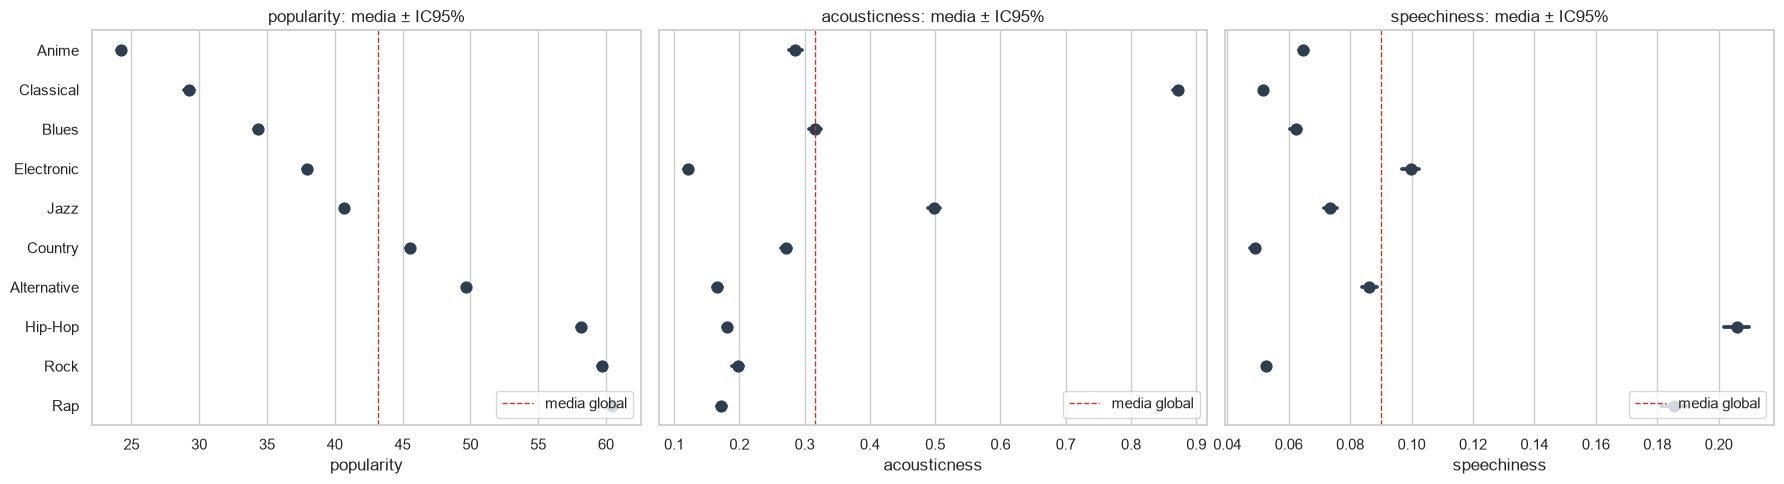

In [11]:
fig = F.grafico_bivariado_objetivo(df, ["popularity", "acousticness", "speechiness"])

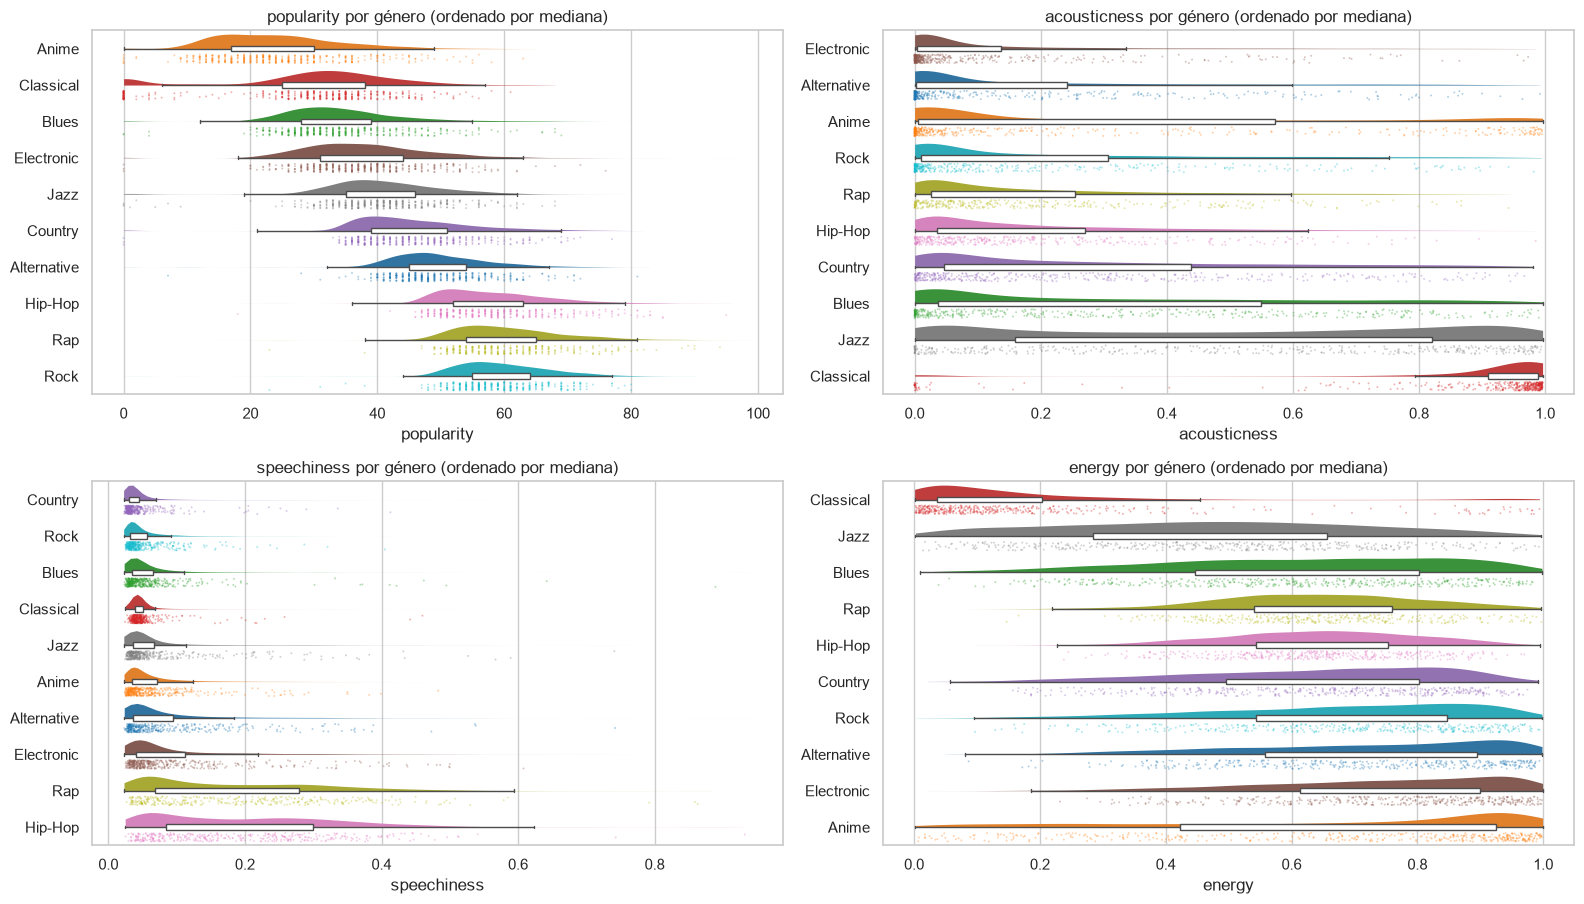

In [12]:
fig = F.grafico_raincloud(df, ["popularity", "acousticness", "speechiness", "energy"])

**Lectura de negocio:**
* `popularity` separa los géneros "mainstream" (Rap, Hip-Hop, Rock, Pop alternativo) de los de nicho (Anime, Classical, Blues, Jazz). Es un efecto de *catálogo*, no acústico, pero es legítimo en producción.
* `acousticness` e `instrumentalness` aíslan a Classical (y parcialmente a Jazz).
* `speechiness` separa Rap/Hip-Hop del resto, pero **no** Rap de Hip-Hop: las dos distribuciones se superponen casi por completo. Es el principal límite de la clasificación.
* `popularity` es la variable con mayor efecto (η² ≈ 0.67) y mayor información mutua: Anime y Classical casi nunca son populares en este catálogo.
* `key` tiene V de Cramér ≈ 0.07 (despreciable). `mode` tiene ≈ 0.22 (moderado): la proporción de tonalidad mayor cambia por género (Country es mayoritariamente *Major*). Ambas se codifican con OneHot.

## 7. EDA multivariado
### 7.1 Correlación jerárquica (Spearman)

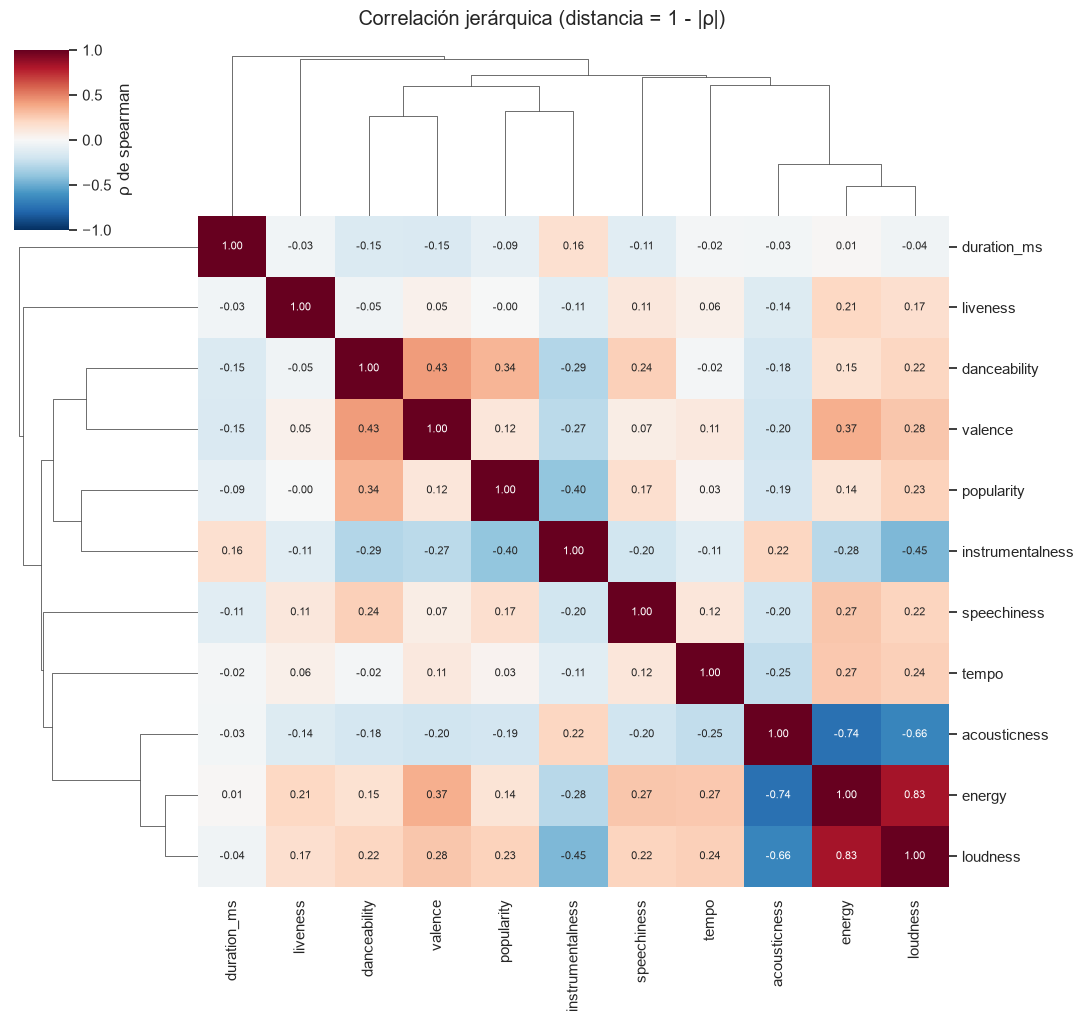

In [13]:
g = F.grafico_correlacion_jerarquica(df, F.COLUMNAS_NUMERICAS)

El clustering forma un bloque **energy–loudness–(−acousticness)** con |ρ| > 0.7: es redundancia que afecta a modelos lineales y a Naive Bayes (que supone independencia condicional), pero no a los árboles. Motiva crear `energia_acustica` e `intensidad` como resúmenes de ese eje.

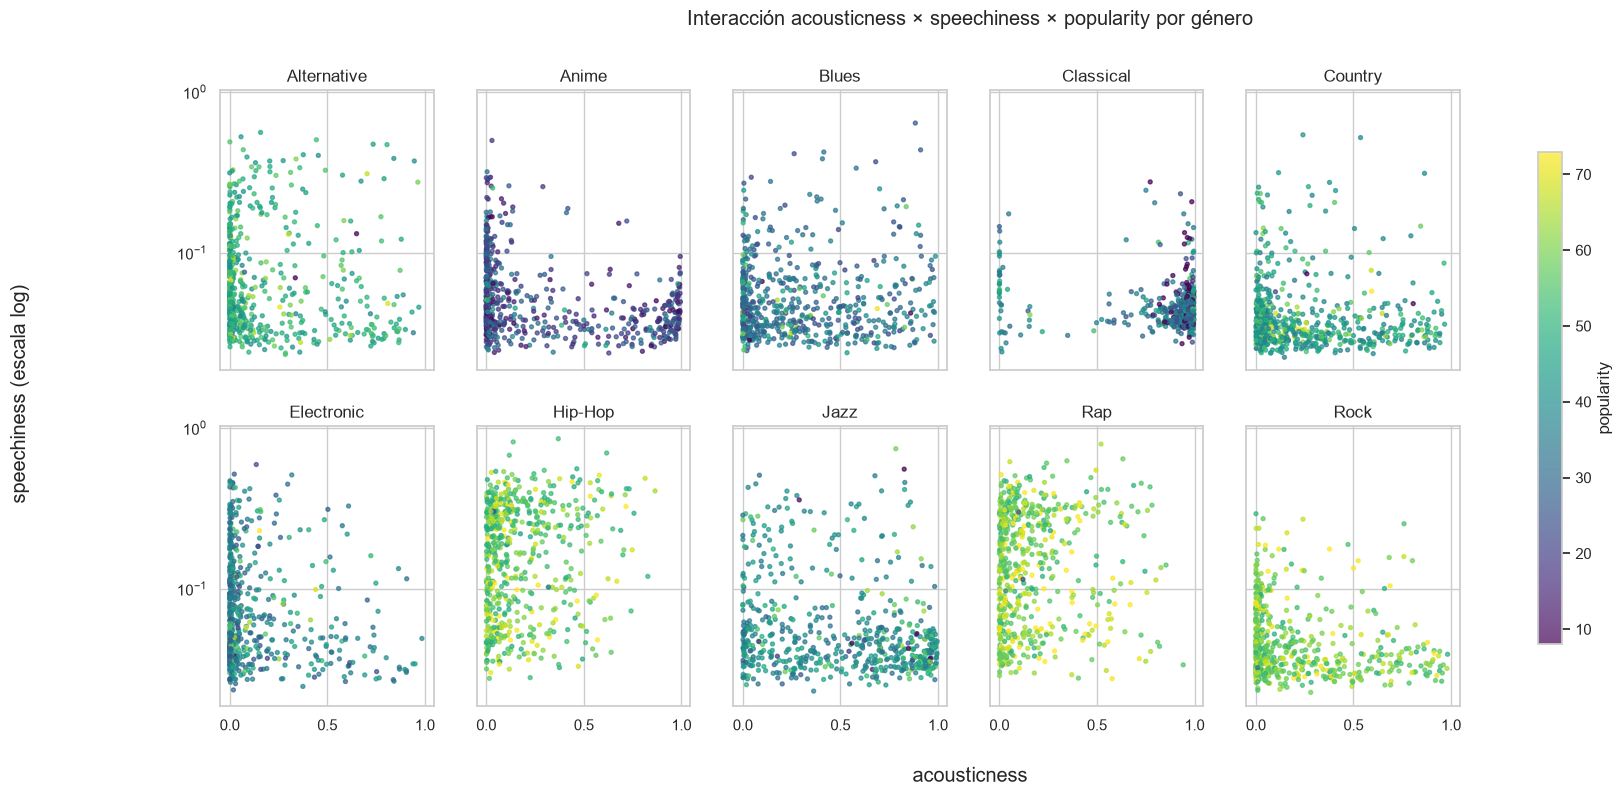

In [14]:
fig = F.grafico_multivariado(df, x="acousticness", y="speechiness", color="popularity")

### 7.2 Separabilidad: PCA y UMAP

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
varianza_acumulada,0.3378,0.4634,0.5582,0.6462,0.7308,0.8037,0.8700,0.9250,0.9670,0.9901


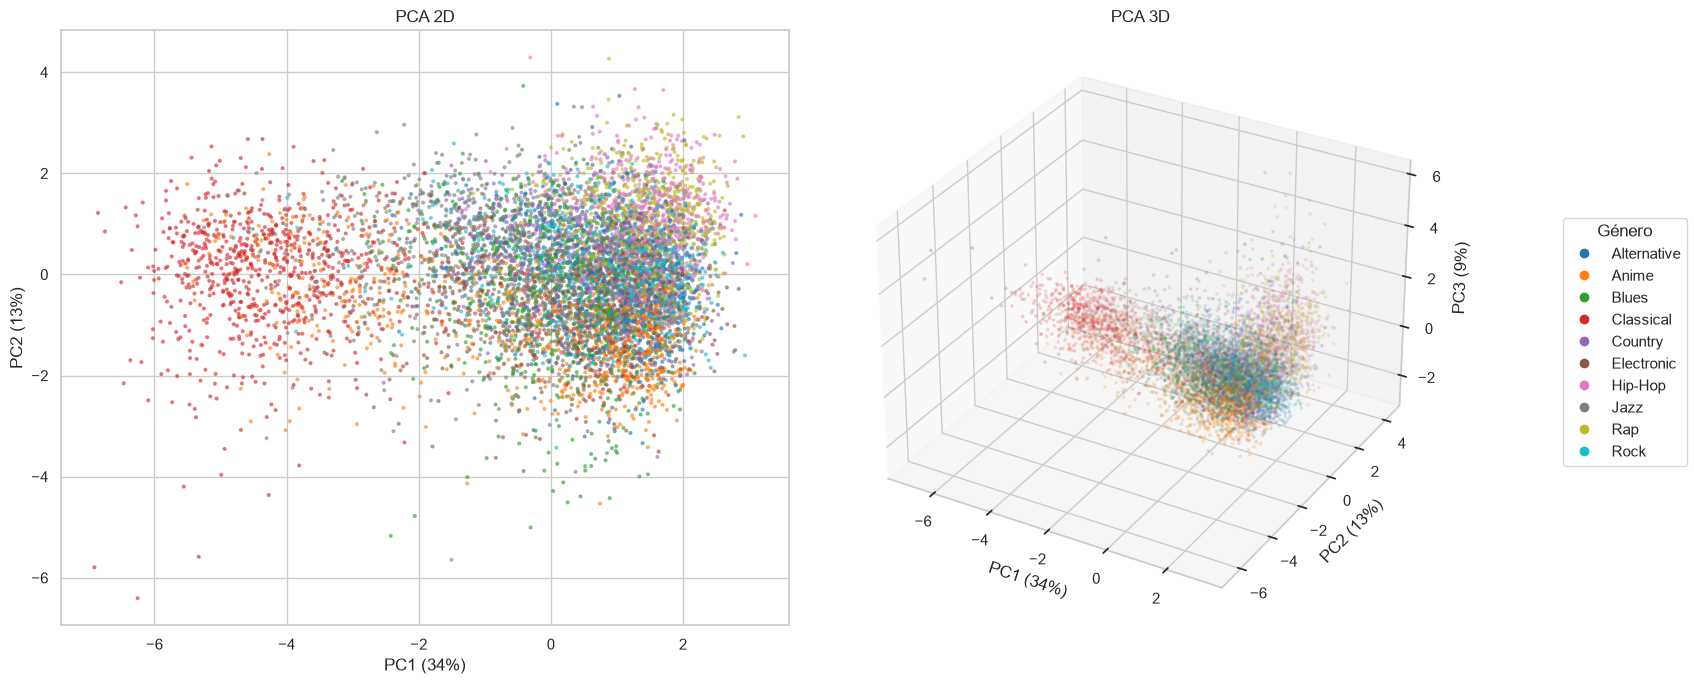

In [15]:
fig, var_exp = F.proyeccion_2d_3d(df, F.COLUMNAS_NUMERICAS, metodo="pca", muestra=4000 if MODO_RAPIDO else 8000)
var_exp.to_frame().T

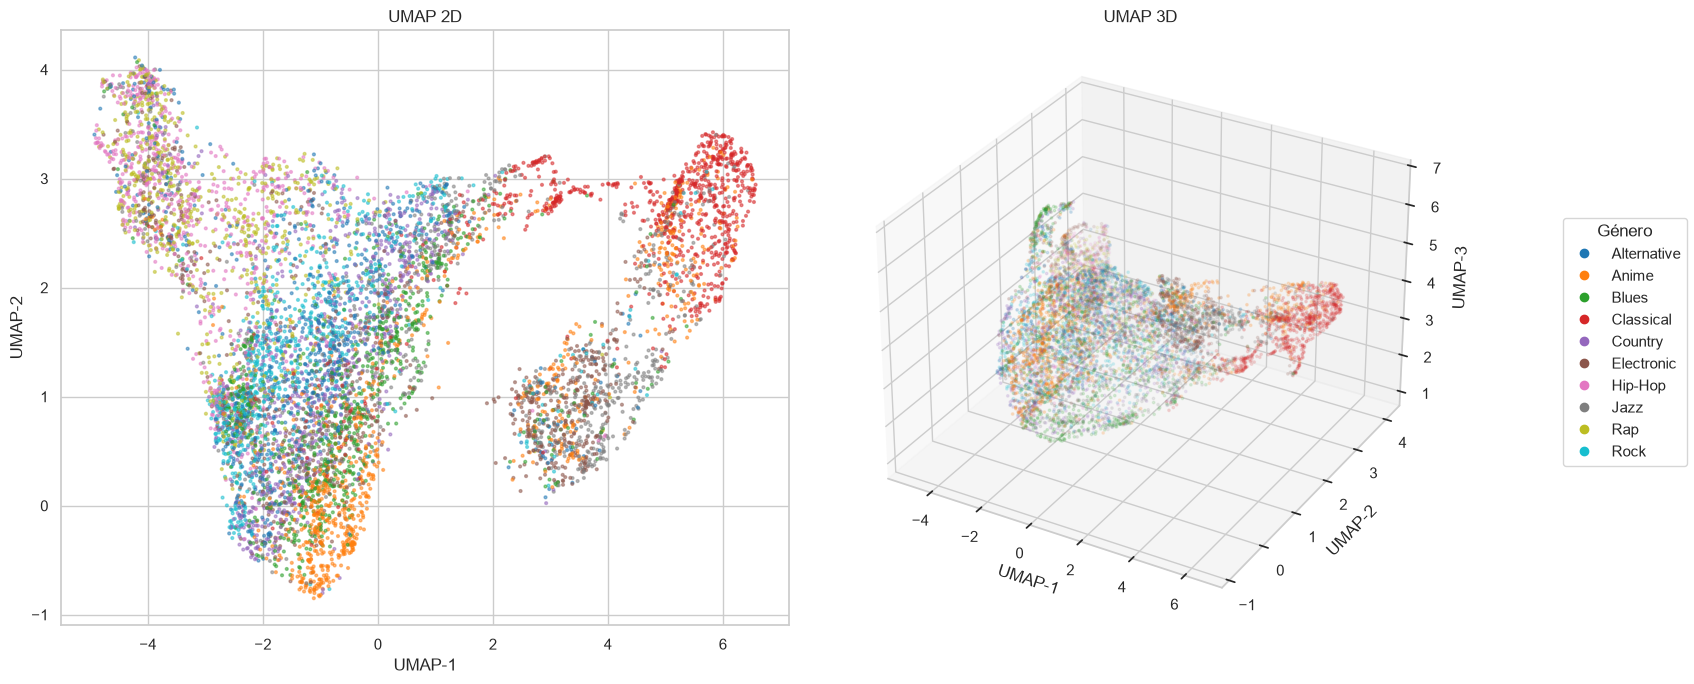

In [16]:
try:
    fig, _ = F.proyeccion_2d_3d(df, F.COLUMNAS_NUMERICAS, metodo="umap", muestra=3000 if MODO_RAPIDO else 8000)
except ImportError:
    print("umap-learn no instalado: se omite la proyección UMAP (pip install umap-learn).")

**Lectura:** 3 componentes lineales explican ~56 % de la varianza y hacen falta 8 para el 90 %: la información está repartida, no concentrada en pocos ejes. Classical, Anime y Electronic forman regiones propias, mientras que Rap/Hip-Hop y Rock/Alternative/Country se solapan. UMAP separa más que PCA, lo que indica **fronteras no lineales** y anticipa que los ensambles de árboles y el MLP superarán a los modelos lineales.

### 7.3 Información mutua (dependencia no lineal con el género)

In [17]:
F.informacion_mutua(df[F.COLUMNAS_NUMERICAS], df[F.OBJETIVO]).to_frame()

,MI
popularity,0.6056
acousticness,0.2952
loudness,0.2926
energy,0.2840
instrumentalness,0.2795
danceability,0.2548
speechiness,0.2055
tempo,0.1480
duration_ms,0.1169
valence,0.1158


## 8. Guardar dataset limpio
Se guarda **sin imputar**: la imputación aprende parámetros y debe ajustarse solo con train (cuadernillo 02).

In [18]:
df.to_csv(rutas.processed / "music_genre_limpio.csv", index=False)
print("Guardado:", rutas.processed / "music_genre_limpio.csv", df.shape)

Guardado: <raíz>\datos\processed\music_genre_limpio.csv (46198, 18)
